# Mount Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
!pip install control

  Using cached control-0.10.2-py3-none-any.whl.metadata (7.6 kB)
Using cached control-0.10.2-py3-none-any.whl (578 kB)


# Non dependents

In [ ]:
import numpy as np
from scipy.signal import fftconvolve, hilbert, firwin, filtfilt, lfilter, resample
from scipy.signal.windows import blackman
from scipy.signal.windows import dpss
from scipy.io import wavfile
import matplotlib.pyplot as plt
import soundfile as sf
import control as ct
from IPython.display import Audio, display, Markdown
import soundfile as sf
from scipy.signal import butter, sosfiltfilt

def speech_shaped_noise(fs, dur, ramp):
    """
    Generate speech-shaped noise approximating ANSI/ASA S3.5 LTASS via
    frequency-domain shaping with random phase and proper Hermitian symmetry.
    """
    N = int(round(dur * fs))
    if N < 2:
        raise ValueError("dur*fs must be at least 2 samples")

    # 1/3-octave LTASS (dB, 1 kHz = 0 dB reference)
    f_centers = np.array([125, 250, 500, 1000, 2000, 4000, 8000, 16000.0])
    levels_dB = np.array([+11.0, +9.7, +9.3, 0.0, -7.7, -15.7, -23.9, -31.0])


    freqs = np.fft.rfftfreq(N, 1.0/fs)          # shape (N//2+1,)
    levels_lin = 10.0**(levels_dB/10.0)
    pow_lin = np.interp(freqs, f_centers, levels_lin,
                        left=levels_lin[0], right=levels_lin[-1])
    amp = np.sqrt(pow_lin)


    amp[0] = 0.0

    rng = np.random.default_rng()
    phi = rng.uniform(0.0, 2*np.pi, size=freqs.shape)
    phi[0] = 0.0
    if N % 2 == 0:         # even length -> Nyquist bin exists at -1
        phi[-1] = 0.0

    spec_pos = amp * np.exp(1j*phi)
    spec_pos[0] = amp[0]           # real
    if N % 2 == 0:
        spec_pos[-1] = amp[-1]     # Nyquist real

    x = np.fft.irfft(spec_pos, n=N)

    ramp_s = int(round(ramp * fs))
    if ramp_s > 0 and 2 * ramp_s < N:
        t = np.arange(ramp_s) / ramp_s
        env = np.ones(N)
        env[:ramp_s] = np.sin(0.5*np.pi * t)**2
        env[-ramp_s:] = np.cos(0.5*np.pi * t)**2
        x *= env

    return x

# Import and Functions

In [ ]:
import numpy as np
from scipy.signal import fftconvolve, hilbert, firwin, filtfilt, lfilter, resample
from scipy.signal.windows import blackman
from scipy.signal.windows import dpss
from scipy.io import wavfile
import matplotlib.pyplot as plt
import soundfile as sf
import control as ct
from IPython.display import Audio, display, Markdown
import soundfile as sf
from scipy.signal import butter, sosfiltfilt

def cams(f):
    """
    Convert a frequency (Hz) to the CAM scale.

    Parameters
    ----------
    f : float or array_like
        Frequency in Hz.

    Returns
    -------
    E : float or ndarray
        CAM scale value.
    """
    return 21.4 * np.log10(0.00437 * f + 1)


def invcams(E):
    """
    Convert a CAM scale value back to frequency in Hz.

    Parameters
    ----------
    E : float or array_like
        CAM scale value.

    Returns
    -------
    f : float or ndarray
        Frequency in Hz.
    """
    return (10 ** (E / 21.4) - 1) / 0.00437


def frames2sig(frames, tail, step):
    """
    Reconstruct a signal from its windowed frames using overlap-add.

    Parameters
    ----------
    frames : ndarray, shape (nw, numwins)
        Array containing windowed frames.
    tail : int
        Number of samples of unframed signal at the end.
    step : int
        Step size in samples between frames.

    Returns
    -------
    sig : ndarray
        Resynthesized signal.
    """
    nw, numwins = frames.shape
    sig_length = (numwins - 1) * step + tail + nw
    sig = np.zeros(sig_length)
    for k in range(numwins):
        start = k * step
        sig[start:start + nw] += frames[:, k]
    return sig


def sig2frames(sig, win, step):
    """
    Extract windowed frames from a continuous signal.

    Parameters
    ----------
    sig : array_like
        Input signal (1D array).
    win : array_like
        Window function (1D array, length nw).
    step : int
        Step size in samples.

    Returns
    -------
    frames : ndarray, shape (nw, numwins)
        Windowed frames (each column is one frame multiplied by the window).
    tail : int
        Number of samples of unframed signal at the end.
    """
    sig = np.asarray(sig)
    win = np.asarray(win)
    nw = len(win)
    numwins = (len(sig) - nw) // step + 1
    tail = len(sig) - ((numwins - 1) * step + nw)
    frames = np.zeros((nw, numwins))
    for k in range(numwins):
        start = k * step
        frames[:, k] = win * sig[start:start + nw]
    return frames, tail


def nextpow2(x):
    """
    Compute the next power of 2 greater than or equal to x.

    Parameters
    ----------
    x : float
        Input value.

    Returns
    -------
    p : int
        The smallest integer p such that 2**p >= x.
    """
    return int(np.ceil(np.log2(x)))


def gammatone_ir(cf, fs, filter_order=4, gt_filter_broadness_factor=1, align=False, L=None):
    """
    Generate the impulse response for a gammatone filter.

    Parameters
    ----------
    cf : float
         Centre frequency in Hz.
    fs : int
         Sampling frequency in Hz.
    filter_order : int, optional
         Filter order (default: 4).
    gt_filter_broadness_factor : float
         Parameter deciding the broadness of the gammatone filter (When x=1, it follows the original erb)
    align : bool, optional
         If True, apply phase alignment so that the impulse response peaks at t=0.
    L : int, optional
         Length of impulse response in samples. If None, it is set to 2**nextpow2(0.128*fs).

    Returns
    -------
    h : ndarray
         The gammatone impulse response.
    tc : float
         The time delay used for phase alignment (0 if align is False).
    """
    if L is None:
        L = 2 ** nextpow2(0.128 * fs)
    # b = 1.019 * 24.7 * (4.37 * cf / 1000 + 1) #calculating ERB
    b = gt_filter_broadness_factor * 24.7 * (4.37 * cf / 1000 + 1)
    tpt = (2 * np.pi) / fs
    gain = ((1.019 * b * tpt) ** filter_order) / 6
    tmp_t = np.arange(L) / fs
    tc = 0
    phase = 0
    if align:
        tc = (filter_order - 1) / (2 * np.pi * b)
        phase = -2 * np.pi * cf * tc
    h = gain * (fs ** 3) * (tmp_t ** (filter_order - 1)) * \
        np.exp(-2 * np.pi * b * tmp_t) * \
        np.cos(2 * np.pi * cf * tmp_t + phase)
    return h, tc


# def gammatoneFast(x, cfs, fs=16000, align=False):
#     """
#     Compute basilar membrane responses using a bank of gammatone filters via FFT convolution.

#     Parameters
#     ----------
#     x : array_like
#         Input signal (1D array).
#     cfs : array_like
#         Centre frequencies for the filter bank (in Hz).
#     fs : int, optional
#         Sampling frequency (default is 16000).
#     align : bool, optional
#         If True, phase alignment is applied so that the impulse responses peak at t=0.

#     Returns
#     -------
#     bm : ndarray
#         Filtered signal matrix. Each column corresponds to one filter output.
#     env : ndarray
#         Instantaneous envelope for each filter output.
#     delay : ndarray
#         Delay (in samples) removed by phase alignment for each filter.
#     """
#     x = np.asarray(x).flatten()
#     cfs = np.asarray(cfs)
#     filter_order = 4
#     L = 2 ** nextpow2(0.128 * fs)
#     numchans = len(cfs)
#     gt = np.zeros((L, numchans))
#     tc = np.zeros(numchans)
#     for i in range(numchans):
#         h, tc_i = gammatone_ir(cfs[i], fs, filter_order=filter_order,gt_filter_broadness_factor=1, align=align, L=L)
#         gt[:, i] = h
#         tc[i] = tc_i
#     # Convolve x with each filter using FFT-based convolution
#     Lbm = len(x) + L - 1
#     bm = np.zeros((Lbm, numchans))
#     for i in range(numchans):
#         bm[:, i] = fftconvolve(x, gt[:, i], mode='full')
#     # Compute Hilbert envelope
#     env = np.abs(hilbert(bm, axis=0))
#     # Delay correction: shift the outputs by the calculated delay
#     delay = np.round(tc * fs).astype(int)
#     for i in range(numchans):
#         d = delay[i]
#         bm[:, i] = np.concatenate((bm[d:, i], np.zeros(d)))
#         env[:, i] = np.concatenate((env[d:, i], np.zeros(d)))
#     return bm, env, delay


def gammatone_gaussian_filter(x, cfs, fs, gt_filter_broadness_factor, align=False): #Added
    """
    Applies Gammatone and Gaussian filtering to an input signal, computes envelopes, qand fine structure

    Parameters:
        x : ndarray
            Input signal
        cfs : ndarray
            Center frequencies of the filters
        fs : int
            Sampling frequency
        align : bool
            Whether to align the impulse responses

    Returns:
        bm : ndarray
            Gammatone-filtered signals
        gtail : ndarray
            Gaussian-filtered signals
        env_gammatone : ndarray
            Gammatone envelope low pass filtered with a blackman window
        env_gaussian : ndarray
            Gaussian tail envelope low pass filtered with a blackman window
        tfs : ndarray
            Carrier from gammatone filter at each center frequency
        delay : ndarray
            Delays applied to each filter
    """
    # Ensure input is a flattened array
    x = np.asarray(x).flatten()
    cfs = np.asarray(cfs)
    filter_order = 4
    L = 2 ** nextpow2(0.128 * fs)
    numchans = len(cfs)

    gt = np.zeros((L, numchans))
    tc = np.zeros(numchans)

    for i in range(numchans):
        h, tc_i = gammatone_ir(cfs[i], fs, 4, gt_filter_broadness_factor, align=align, L=L)
        gt[:, i] = h
        tc[i] = tc_i

    Lbm = len(x)
    bm = np.zeros((Lbm, numchans))
    for i in range(numchans):
        bm[:, i] = fftconvolve(x, gt[:, i], mode='same')
    env_gammatone = np.maximum(bm, 0)

    coeffs = np.zeros((101, numchans))
    for i in range(numchans):
        coeff = firwin(101, min((gt_filter_broadness_factor*((24.7 * (4.37 * cfs[i] / 1000 + 1))/2)), 300), window='blackman', fs=fs)
        coeffs[:, i] = coeff
        env_gammatone_blackman = filtfilt(coeff, [1.0], env_gammatone[:,i], axis=0)
        env_gammatone[:,i] = env_gammatone_blackman

    tfs_gammatone = np.cos(np.unwrap(np.angle(hilbert(bm, axis = 0))))

    delay = np.round(tc * fs).astype(int)
    for i in range(numchans):
        d = delay[i]
        bm[:, i] = np.concatenate((bm[d:, i], np.zeros(d)))
        env_gammatone[:, i] = np.concatenate((env_gammatone[d:, i], np.zeros(d)))
        tfs_gammatone[:, i] = np.concatenate((tfs_gammatone[d:, i], np.zeros(d)))

    # def gaussian_filter(signal, fs, center_freq, bandwidth, center_factor=1.0, pad_mult=2):
    #     N = len(signal)
    #     c = center_factor * center_freq

    #     Nfft = 1 << int(np.ceil(np.log2(max(N, 1) * pad_mult)))
    #     freqs = np.fft.fftfreq(Nfft, d=1.0/fs)

    #     shifted_cf = 0.7 * center_freq # Shift center frequency for Gaussian filter to 0.7*cf
    #     sigma = bandwidth / (2 * np.sqrt(2 * np.log(2))+ 1e-20)  # Convert bandwidth to std dev

    #     gaussian_filter =  np.exp(-0.5 * ((freqs - c) / (sigma + 1e-20))**2) \
    #                       + np.exp(-0.5 * ((freqs + c) / (sigma + 1e-20))**2)

    #     gaussian_filter /= (gaussian_filter.max() + 1e-12)

    #     xpad = np.zeros(Nfft, dtype=float)
    #     xpad[:N] = x

    #     X = np.fft.fft(xpad)
    #     filtered_sig = np.fft.ifft(X * gaussian_filter).real
    #     return filtered_sig[:N]

    def gaussian_filter(signal, fs, center_freq=632, bandwidth_oct=3.17, pad_mult=2):
      """
      Log-frequency Gaussian bandpass filter.

      Parameters:
          signal      : input audio signal
          fs          : sample rate (Hz)
          center_freq : center frequency in Hz (geometric mean of band)
                        default 632 Hz = sqrt(200 * 2000)
          bandwidth_oct: bandwidth in octaves (FWHM)
                        default 3.17 octaves spans ~200 to ~2000 Hz
          pad_mult    : zero-padding multiplier for FFT
      """
      N = len(signal)
      Nfft = 1 << int(np.ceil(np.log2(max(N, 1) * pad_mult)))
      freqs = np.fft.fftfreq(Nfft, d=1.0 / fs)

      sigma_oct = bandwidth_oct / (2 * np.sqrt(2 * np.log(2)))

      H = np.zeros(Nfft)

      pos = freqs > 0
      neg = freqs < 0
      H[pos] = np.exp(-0.5 * (np.log2(freqs[pos]  / center_freq) / sigma_oct) ** 2)
      H[neg] = np.exp(-0.5 * (np.log2(-freqs[neg] / center_freq) / sigma_oct) ** 2)

      # pos_mask = freqs > 0
      # log_freqs_pos = np.log2(freqs[pos_mask] / center_freq)
      # H[pos_mask] = np.exp(-0.5 * (log_freqs_pos / sigma_oct) ** 2)

      # neg_mask = freqs < 0
      # log_freqs_neg = np.log2(-freqs[neg_mask] / center_freq)
      # H[neg_mask] = np.exp(-0.5 * (log_freqs_neg / sigma_oct) ** 2)

      H /= (H.max() + 1e-12)

      xpad = np.zeros(Nfft, dtype=float)
      xpad[:N] = signal

      X = np.fft.fft(xpad)
      filtered_sig = np.fft.ifft(X * H).real
      return filtered_sig[:N]

    def butterworth_lpf(signal, cf, fs, order=8):
        erb = 24.7 * (4.37 * cf / 1000 + 1)
        cutoff = min(cf + erb / 2, fs / 2 - 100)
        sos = butter(order, cutoff, btype='low', fs=fs, output='sos')
        return sosfiltfilt(sos, signal)

    gtail = np.zeros_like(bm)
    env_gaussian = np.zeros_like(env_gammatone)

    coeff_gauss  = firwin(101, 300, window='blackman', fs=fs)
    gauss_signal = gaussian_filter(x, fs)

    for i, cf in enumerate(cfs):
        gated          = butterworth_lpf(gauss_signal, cf, fs)
        gtail[:, i]    = gated
        env_gaussian[:, i] = filtfilt(coeff_gauss, [1.0], np.maximum(gated, 0))

    return bm, gtail, env_gammatone, env_gaussian, tfs_gammatone, delay


def rmsnormalize(x):
    """
    Normalize the input signal to have an RMS of 0.1.

    Parameters
    ----------
    x : array_like
        Input signal.

    Returns
    -------
    y : ndarray
        RMS-normalized signal.
    """
    x = np.asarray(x)
    r = np.sqrt(np.mean(x ** 2))
    return x * (0.1 / r)


def rampsound(x, fs, risetime):
    """
    Apply a ramp to a sound signal using a DPSS window.

    Parameters
    ----------
    x : array_like
        Input sound signal.
    fs : int
        Sampling frequency in Hz.
    risetime : float
        Rise time in seconds.

    Returns
    -------
    y : ndarray
        The ramped sound signal.
    """
    x = np.asarray(x)
    Nramp = int(np.ceil(fs * risetime * 2)) + 1
    w = dpss(Nramp, 1, sym=True)
    w = w - w[0]
    w = w / np.max(w)
    half = int(np.ceil(Nramp / 2))
    ones_length = max(len(x) - 2 * half, 0)
    wbig = np.concatenate((w[:half], np.ones(ones_length), w[-half:]))
    return x * wbig


def pow2db(x):
    """
    Convert power values to decibels (dB).

    Parameters
    ----------
    x : array_like
        Power values.

    Returns
    -------
    y : array_like
        Values in decibels.
    """
    return 10 * np.log10(x)

def itfs(noisy, oracle, noise, LC, fs, nfilts=128):
    """
    Apply ideal time-frequency segregation (ITFS) using binary masking on a gammatone filter bank representation.

    Parameters
    ----------
    noisy : array_like
        The target-masker mixture signal.
    oracle : array_like
        The clean target signal (same length as noisy).
    noise : array_like
        The noise signal such that oracle + noise equals the mixture.
    LC : float
        Local SNR criterion (in dB).
    fs : int
        Sampling frequency.
    nfilts : int, optional
        Number of filter bank channels (default is 128).

    Returns
    -------
    masked : ndarray
        The cleaned mixture after applying ITFS.
    """
    f_low = 80
    f_high = 8000
    cfs = invcams(np.linspace(cams(f_low), cams(f_high), nfilts))
    noisy = np.asarray(noisy).flatten()
    oracle = np.asarray(oracle).flatten()
    noise = np.asarray(noise).flatten()
    print('Extracting basilar membrane filter outputs!')
    bm_mix, _, _ = gammatoneFast(noisy, cfs, fs, align=True)
    bm_T, _, _   = gammatoneFast(oracle, cfs, fs, align=True)
    bm_N, _, _   = gammatoneFast(noise, cfs, fs, align=True)

    win_ms = 20
    win_overlap_ms = 10
    win = blackman(int(np.ceil(fs * win_ms * 1e-3)))
    step = int(np.ceil(fs * win_overlap_ms * 1e-3))

    masked = np.zeros_like(bm_mix)
    for k in range(nfilts):
        print(f'Processing filter # {k+1} / {nfilts}')
        frames_mix, _ = sig2frames(bm_mix[:, k], win, step)
        frames_T, _   = sig2frames(bm_T[:, k], win, step)
        frames_N, tail = sig2frames(bm_N[:, k], win, step)
        SNR = pow2db(np.mean(frames_T ** 2, axis=0)) - pow2db(np.mean(frames_N ** 2, axis=0))
        mask_bin = SNR > LC
        frames_masked = frames_mix * mask_bin
        masked[:, k] = frames2sig(frames_masked, tail, step)
    masked_sum = np.sum(masked, axis=1)
    return rmsnormalize(masked_sum)


def extract_envelope(signal, fs, cutoff=300, numtaps=101):
    """
    Extract the envelope of a signal by half-wave rectification followed by zero-phase low-pass filtering.

    Parameters
    ----------
    signal : array_like
        Input signal (1D array) from which to extract the envelope.
    fs : int
        Sampling frequency in Hz.
    cutoff : float, optional
        Cutoff frequency of the low-pass filter in Hz (default is 300 Hz).
    numtaps : int, optional
        Number of taps for the FIR low-pass filter (default is 101).

    Returns
    -------
    env : ndarray
        The extracted envelope.
    """
    rectified = np.maximum(signal, 0)
    taps = firwin(numtaps, cutoff, window='blackman', fs=fs)
    # Zero-phase filtering to avoid group delay
    env = filtfilt(taps, [1.0], rectified)
    return env

def noisevocode(x, fs, ttr,phase_diff=False, bw_broadness_factor=1, nfilts=24):
    """
    Apply noise vocoding using a gammatone filter bank analysis, envelope extraction,
    and resynthesis via broadband noise modulation.

    Procedure:
      1. Filter the input signal with a gammatone filter bank (channels equally spaced between 80 and 8000 Hz).
      2. For each channel, half-wave rectify the output and extract its envelope using zero-phase low-pass filtering.
      3. Generate broadband white noise and modulate it with the extracted envelope.
      4. Re-filter the modulated noise using the corresponding gammatone filter (using zero-phase filtering).
      5. RMS-match each channel to the original gammatone-filtered output.
      6. Sum across channels to produce the final noise-vocoded speech.

    Parameters
    ----------
    x : array_like
        Input sound signal (1D array).
    fs : int
        Sampling frequency in Hz.
    ttr : int
        Tip-to-tail ratio
    snr : int
        Signal-to-noise ratio in dB (default is 6 dB).
    nfilts : int, optional
        Number of channels (default is 24). Channels are equally spaced between 80 Hz and 8000 Hz.

    Returns
    -------
    nv : ndarray
        Noise-vocoded speech signal.
    """
    x = np.array(x)
    f_low = 80
    f_high = 8000
    cfs = invcams(np.linspace(cams(f_low), cams(f_high), nfilts))

    # Analyze the input signal using the gammatone filter bank.
    bm, gtail, env_gammatone, env_gaussian, tfs, _ = gammatone_gaussian_filter(x, cfs, fs,bw_broadness_factor, align=True)

    vocoded_channels = []
    eps = 1e-12

    for i in range(nfilts):
        channel_signal = bm[:, i]
        tfs_signal = tfs[:,i]
        env_gamma = env_gammatone[:,i]
        env_gauss = env_gaussian[:,i]

        env_gamma_rms = np.sqrt(np.mean(env_gamma**2) + eps)
        env_gauss_rms = np.sqrt(np.mean(env_gauss**2) + eps)
        env_gamma_norm = env_gamma / env_gamma_rms # Normalize the gammatone envelope
        env_gauss_norm = env_gauss / env_gauss_rms  # Normalize the Gaussian envelope

        s1 = env_gamma_norm * tfs_signal
        s2 = env_gauss_norm * tfs_signal
        r1 = np.sqrt(np.mean(s1**2) + eps)
        r2 = np.sqrt(np.mean(s2**2) + eps)

        # combine envelopes - if cf < 1000Hz, just gammatone, else combine with gaussian [April 22, 2025]
        if cfs[i] < 1000:
            env = env_gamma_norm
        else:
            scaling = 1 / ct.db2mag(ttr)
            env = env_gamma_norm + ((scaling * env_gauss_norm)*(r1/r2))

        # Modulate speech with the extracted envelope.
        modulated_speech = tfs_signal * env

        # Match the RMS of the vocoded channel to that of the original channel.
        orig_rms = np.sqrt(np.mean(channel_signal ** 2))
        vocoded_rms = np.sqrt(np.mean(modulated_speech ** 2))
        scale = orig_rms / vocoded_rms if vocoded_rms > 0 else 0
        modulated_speech *= scale

        vocoded_channels.append(modulated_speech)

    # Sum across channels to produce the final noise-vocoded output.
    nv = np.sum(np.column_stack(vocoded_channels), axis=1)

    nv = rampsound(nv, fs, risetime=0.25)
    nv /= np.max(np.abs(nv),axis=0)
    return nv

In [ ]:
import os, random, csv

ROOT = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio"
i = 0
ttrs = [40, 30, 20, 10, 0, -10]
snrs = [-24, -18, -12, -6, 0, 3, 6, 12]

for ttr in ttrs:
    print(f"Processing TTR = {ttr} dB")

    for snr in snrs:
        for n in range(1):
          print(f"TTR = {ttr}, SNR = {snr} dB")
          audio = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/F1/F1_b2_w1_orig.wav"
          fname = "F1_b01_w1_orig"
          print(f"    Processing {fname}")
          i += 1
          rate, audio =  wavfile.read(audio)
          audio = audio.astype(np.float32)

          duration_seconds = (audio.shape[0]) / rate
          duration_seconds = duration_seconds + 1
          speech_noise = speech_shaped_noise(rate, duration_seconds, 0)

          signal_power = np.mean(audio**2)
          noise_power = np.mean(speech_noise**2)

          # Calculate scaling factor for noise to achieve desired SNR
          snr_linear = ct.db2mag(snr)
          desired_noise_power = signal_power / snr_linear
          scale_factor = (np.sqrt(desired_noise_power / noise_power))
          padding = len(speech_noise) - len(audio)
          audio_paddedtonoise = np.concatenate((np.zeros(padding), audio))
          noise_scaled = speech_noise * scale_factor
          noisy_signal = audio_paddedtonoise + noise_scaled
          nv = noisevocode(noisy_signal, rate, ttr=ttr, nfilts=24)
          nv = nv[500:]
          output_filename = f"{fname}_ttr{ttr}_snr{snr}.wav"
          # output_path = os.path.join(ROOT, "Vocoded_stimulus", output_filename)
          print(n)

          # label = f"{ttr}_gammatonetip_{bw_broadness_factor:.2f}_snr5"
          # if ttr == 40 or ttr == 0 or ttr == -10:
          display(Markdown(f"**{output_filename}**"))
          display(Audio(nv[500:], rate=rate))
          # sf.write(f'/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/Milestone2/SharadhiMar2026_{fname}_ttr{ttr}_snr{snr}.wav', nv, rate)
          # print(f"    Saved")

# torch instead of scipy

In [ ]:
import numpy as np
import math
import torch
import torchaudio.functional as F
from scipy.signal import butter, lfilter_zi

def cams(f):
    """
    Convert a frequency (Hz) to the CAM scale.

    Parameters
    ----------
    f : float or array_like
        Frequency in Hz.

    Returns
    -------
    E : float or ndarray
        CAM scale value.
    """
    return 21.4 * np.log10(0.00437 * f + 1)


def invcams(E):
    """
    Convert a CAM scale value back to frequency in Hz.

    Parameters
    ----------
    E : float or array_like
        CAM scale value.

    Returns
    -------
    f : float or ndarray
        Frequency in Hz.
    """
    return (10 ** (E / 21.4) - 1) / 0.00437


def frames2sig(frames, tail, step):
    """
    Reconstruct a signal from its windowed frames using overlap-add.

    Parameters
    ----------
    frames : ndarray, shape (nw, numwins)
        Array containing windowed frames.
    tail : int
        Number of samples of unframed signal at the end.
    step : int
        Step size in samples between frames.

    Returns
    -------
    sig : ndarray
        Resynthesized signal.
    """
    nw, numwins = frames.shape
    sig_length = (numwins - 1) * step + tail + nw
    sig = np.zeros(sig_length)
    for k in range(numwins):
        start = k * step
        sig[start:start + nw] += frames[:, k]
    return sig


def sig2frames(sig, win, step):
    """
    Extract windowed frames from a continuous signal.

    Parameters
    ----------
    sig : array_like
        Input signal (1D array).
    win : array_like
        Window function (1D array, length nw).
    step : int
        Step size in samples.

    Returns
    -------
    frames : ndarray, shape (nw, numwins)
        Windowed frames (each column is one frame multiplied by the window).
    tail : int
        Number of samples of unframed signal at the end.
    """
    sig = np.asarray(sig)
    win = np.asarray(win)
    nw = len(win)
    numwins = (len(sig) - nw) // step + 1
    tail = len(sig) - ((numwins - 1) * step + nw)
    frames = np.zeros((nw, numwins))
    for k in range(numwins):
        start = k * step
        frames[:, k] = win * sig[start:start + nw]
    return frames, tail


def nextpow2(x):
    """
    Compute the next power of 2 greater than or equal to x.

    Parameters
    ----------
    x : float
        Input value.

    Returns
    -------
    p : int
        The smallest integer p such that 2**p >= x.
    """
    return int(np.ceil(np.log2(x)))

def gammatone_ir(cf, fs, filter_order=4, gt_filter_broadness_factor=1, align=False, L=None):
    """
    Generate the impulse response for a gammatone filter.

    Parameters
    ----------
    cf : float
         Centre frequency in Hz.
    fs : int
         Sampling frequency in Hz.
    filter_order : int, optional
         Filter order (default: 4).
    gt_filter_broadness_factor : float
         Parameter deciding the broadness of the gammatone filter (When x=1, it follows the original erb)
    align : bool, optional
         If True, apply phase alignment so that the impulse response peaks at t=0.
    L : int, optional
         Length of impulse response in samples. If None, it is set to 2**nextpow2(0.128*fs).

    Returns
    -------
    h : ndarray
         The gammatone impulse response.
    tc : float
         The time delay used for phase alignment (0 if align is False).
    """

    if not torch.is_tensor(cf):
        cf = torch.tensor(cf, dtype=torch.float64)
    device, dtype = cf.device, cf.dtype
    if not torch.is_tensor(gt_filter_broadness_factor): #currently b which could use gt_broadness_factor has been hardcoded to 1
        gt_filter_broadness_factor = torch.tensor(gt_filter_broadness_factor, dtype=cf.dtype, device=cf.device)


    if L is None:
      L = 2 ** nextpow2(0.128*fs)
    # b = gt_filter_broadness_factor * (24.7 * cf / 1000 + 1)
    b = 1.019 * 24.7 * (4.37 * cf / 1000 + 1)
    tpt = (2* np.pi) / fs
    gain = ((1.019 * b * tpt) ** filter_order) / 6
    tmp_t = torch.arange(L, dtype=dtype, device=device) / fs
    if align:
        tc = (filter_order - 1) / (2 * np.pi * b)
        phase = -2 * np.pi * cf * tc
    else:
        tc = torch.zeros_like(b)
        phase = torch.zeros_like(b)
    h = gain * (fs ** 3) * (tmp_t ** (filter_order - 1)) * \
        torch.exp(-2 * np.pi * b * tmp_t) * \
        torch.cos(2 * np.pi * cf * tmp_t + phase)
    return h, tc


def hilbert_transform(x, axis=0):
  """
  Computes hilbert tranform in torch because there is no inbuilt hilbert transform in torch or torchaudio
  """

  if not torch.is_tensor(x):
      x = torch.tensor(x, dtype=dtype, device=device)
  device, dtype = x.device, x.dtype

  N = x.shape[axis]
  if N <= 1:
      raise ValueError("Input signal must have at least 2 samples.")

  Xf = torch.fft.fft(x, n=N, dim=axis)

  h = torch.zeros(N, dtype=x.dtype)
  if N % 2 == 0:
    h[0] = 1
    h[N // 2] = 1
    h[1:N // 2] = 2

  else:
    h[0] = 1
    h[1:(N + 1) // 2] = 2

  shape = [1] * x.dim()
  shape[axis] = N
  h = h.view(shape)

  return torch.fft.ifft(Xf * h, n=N, dim=axis)


def gammatoneFast(x, cfs, fs, filter_order=4, gt_filter_broadness_factor=1, align=False):
    """
    Compute basilar membrane responses using a bank of gammatone filters via FFT convolution.

    Parameters
    ----------
    x : array_like
        Input signal (1D array).
    cfs : array_like
        Centre frequencies for the filter bank (in Hz).
    fs : int, optional
        Sampling frequency (default is 16000).
    align : bool, optional
        If True, phase alignment is applied so that the impulse responses peak at t=0.

    Returns
    -------
    bm : ndarray
        Filtered signal matrix. Each column corresponds to one filter output.
    env : ndarray
        Instantaneous envelope for each filter output.
    delay : ndarray
        Delay (in samples) removed by phase alignment for each filter.
    """

    if not torch.is_tensor(x):
        x = torch.tensor(x, dtype=dtype, device=device)
    if not torch.is_tensor(cfs):
        cfs = torch.tensor(cfs, dtype=dtype, device=device)

    device, dtype = x.device, x.dtype

    filter_order = 4
    L = 2 ** nextpow2(0.128*fs)
    numchans = len(cfs)
    bm = torch.zeros((len(x), numchans), dtype=dtype, device=device)
    gt = torch.zeros((L, numchans), dtype=dtype, device=device)
    tc = torch.zeros(numchans, dtype=dtype, device=device)
    gt_list = []
    tc_list = []
    for i in range(numchans):
        h, tc_i = gammatone_ir(cfs[i], fs, filter_order=filter_order, gt_filter_broadness_factor=1, align=align, L=L)
        gt_list.append(h)
        tc_list.append(tc_i)
    gt = torch.stack(gt_list, dim=1)
    tc = torch.stack(tc_list)

    bm_list = []
    for i in range(numchans):
        bm_list.append(F.fftconvolve(x, gt[:, i]))
    bm = torch.stack(bm_list, dim=1)

    env = torch.abs(hilbert_transform(bm, axis = 0))

    delay = torch.round(tc * fs).to(torch.long)
    bm_shifted = []
    env_shifted = []
    for i in range(numchans):
        d = delay[i].item()
        bm_shifted.append(torch.cat((bm[d:, i], torch.zeros(d, dtype=bm.dtype))))
        env_shifted.append(torch.cat((env[d:, i], torch.zeros(d, dtype=env.dtype))))
    bm = torch.stack(bm_shifted, dim=1)
    env = torch.stack(env_shifted, dim=1)

    return bm, env, delay


def rampsound(x, fs, risetime):
    """
    Apply a ramp to a sound signal using a DPSS window.

    Parameters
    ----------
    x : array_like
        Input sound signal.
    fs : int
        Sampling frequency in Hz.
    risetime : float
        Rise time in seconds.

    Returns
    -------
    y : ndarray
        The ramped sound signal.
    """

    if not torch.is_tensor(x):
        x = torch.tensor(x, dtype=dtype)

    Nramp = int(math.ceil(fs * risetime * 2)) + 1
    w = torch.tensor(dpss(Nramp, 1, sym=True), dtype=x.dtype)   # scipy design step, fixed window
    w = w - w[0]
    w = w / torch.max(w)
    half = int(math.ceil(Nramp / 2))
    ones_length = max(x.shape[0] - 2 * half, 0)
    wbig = torch.cat((w[:half], torch.ones(ones_length, dtype=x.dtype), w[-half:]))
    return x * wbig


def firwin_torch(numtaps, cutoff, fs, pass_zero=True, window='blackman', dtype=torch.float64):
    """
    Firwin implementation using torch.
    """

    assert numtaps % 2 == 1, "Number of taps must be odd"
    assert pass_zero in (True, False), "pass_zero must be True or False"

    fc = cutoff/fs
    M = numtaps - 1
    n = torch.arange(numtaps, dtype=dtype) - M / 2.0

    h = torch.zeros(numtaps, dtype=dtype)
    if window == 'blackman':
      w = torch.blackman_window(numtaps, periodic=False, dtype = dtype)
    elif window == 'hamming':
      w = torch.hamming_window(numtaps, periodic=False, dtype = dtype)
    elif window == 'hann':
      w = torch.hann_window(numtaps, periodic=False, dtype = dtype)
    else:
      raise ValueError("Invalid window type")

    h = 2*fc*torch.sinc(2*fc*n)
    h = h * w
    h = h / torch.sum(h)
    return h


def unwrap_torch(p, dim=-1, discont=None):
    """
    Torch equivalent of np.unwrap
    """
    if discont is None:
      discont = torch.pi

    dp = torch.diff(p, dim=dim)
    dp_mod = torch.remainder(dp + torch.pi, 2 * torch.pi) - torch.pi

    boundary = (dp_mod == -torch.pi) & (dp>0)
    dp_mod = torch.where(boundary, torch.full_like(dp_mod, torch.pi), dp_mod)

    dp_corr = dp_mod - dp
    dp_corr = torch.where(torch.abs(dp) < discont, torch.zeros_like(dp_corr), dp_corr)

    cumsum_corr = torch.cumsum(dp_corr, dim=dim)

    shape = list(p.shape)
    shape[dim] = 1
    zero = torch.zeros(shape, dtype=p.dtype, device=p.device)
    cumsum_corr = torch.cat([zero, cumsum_corr], dim=dim)

    return p + cumsum_corr


def gammatone_gaussian_filter(x, cfs, fs, gt_filter_broadness_factor=1.091, align=False): #Added
    """
    Applies Gammatone and Gaussian filtering to an input signal, computes envelopes, qand fine structure

    Parameters:
        x : ndarray
            Input signal
        cfs : ndarray
            Center frequencies of the filters
        fs : int
            Sampling frequency
        align : bool
            Whether to align the impulse responses

    Returns:
        bm : ndarray
            Gammatone-filtered signals
        gtail : ndarray
            Gaussian-filtered signals
        env_gammatone : ndarray
            Gammatone envelope low pass filtered with a blackman window
        env_gaussian : ndarray
            Gaussian tail envelope low pass filtered with a blackman window
        tfs : ndarray
            Carrier from gammatone filter at each center frequency
        delay : ndarray
            Delays applied to each filter
    """

    if not torch.is_tensor(x):
        x = torch.tensor(x, dtype=torch.float64)
    if not torch.is_tensor(cfs):
        cfs = torch.tensor(cfs, dtype=x.dtype)

    device, dtype = x.device, x.dtype

    filter_order = 4
    L = 2 ** nextpow2(0.128*fs)
    numchans = len(cfs)
    bm = torch.zeros((len(x), numchans), dtype=dtype, device=device)
    gtail = torch.zeros((len(x), numchans), dtype=dtype, device=device)
    env_gammatone = torch.zeros((len(x), numchans), dtype=dtype, device=device)
    env_gaussian = torch.zeros((len(x), numchans), dtype=dtype, device=device)
    tfs = torch.zeros((len(x), numchans), dtype=dtype, device=device)
    delay = torch.zeros(numchans, dtype=dtype, device=device)
    bm_list = []
    gtail_list = []
    env_gammatone_list = []
    env_gaussian_list = []
    tfs_list = []
    delay_list = []
    tc = torch.zeros(numchans, dtype=dtype, device=device)
    gt_list = []
    tc_list = []
    for i in range(numchans):
        h, tc_i = gammatone_ir(cfs[i], fs, filter_order=4, gt_filter_broadness_factor=gt_filter_broadness_factor, align=align, L=L)
        gt_list.append(h)
        tc_list.append(tc_i)
    gt = torch.stack(gt_list, dim=1)
    tc = torch.stack(tc_list)

    bm_list = []
    for i in range(numchans):
        bm_list.append(F.fftconvolve(x, gt[:, i], mode='same'))
    bm = torch.stack(bm_list, dim=1)
    env_gammatone = torch.clamp(bm, min=0)

    coeff_list = []
    env_gammatone_list = []
    coeff = torch.zeros((101, numchans))
    a_coeffs = torch.zeros(101, dtype=torch.float64)
    a_coeffs[0] = 1.0
    for i in range(numchans):
      coeff = firwin_torch(101, torch.clamp((gt_filter_broadness_factor*((24.7*(4.37*cfs[i] / 1000 +1))/2)), max=300), window='blackman', fs=fs)
      coeff_list.append(coeff)
      env_gammatone_blackman = F.filtfilt(env_gammatone[:, i], a_coeffs, coeff, clamp=False)
      env_gammatone_list.append(env_gammatone_blackman)

    env_gammatone = torch.stack(env_gammatone_list, dim=1)
    coeff = torch.stack(coeff_list, dim=1)

    tfs_gammatone = torch.cos(unwrap_torch(torch.angle(hilbert_transform(bm, axis=0)), dim=0))

    delay = torch.round(tc * fs).to(torch.long)
    bm_shifted = []
    env_gammatone_shifted = []
    tfs_shifted = []
    for i in range(numchans):
        d = delay[i].item()
        bm_shifted.append(torch.cat((bm[d:, i], torch.zeros(d, dtype=bm.dtype))))
        env_gammatone_shifted.append(torch.cat((env_gammatone[d:, i], torch.zeros(d, dtype=env_gammatone.dtype))))
        tfs_shifted.append(torch.cat((tfs_gammatone[d:, i], torch.zeros(d, dtype=tfs_gammatone.dtype))))
    bm = torch.stack(bm_shifted, dim=1)
    env_gammatone = torch.stack(env_gammatone_shifted, dim=1)
    tfs_gammatone = torch.stack(tfs_shifted, dim=1)


    def gaussian_filter(signal, fs, center_freq=632, bandwidth_oct=3.17, pad_mult=2):

      device, dtype = signal.device, signal.dtype

      if not torch.is_tensor(signal):
          signal = torch.tensor(signal, dtype=dtype, device=device)
      if not torch.is_tensor(center_freq):
          center_freq = torch.tensor(center_freq, dtype=dtype, device=device)
      if not torch.is_tensor(bandwidth_oct):
          bandwidth_oct = torch.tensor(bandwidth_oct, dtype=dtype, device=device)
      if not torch.is_tensor(pad_mult):
          pad_mult = torch.tensor(pad_mult, dtype=dtype, device=device)

      N = signal.shape[-1]
      Nfft = 1 << int(torch.ceil(torch.log2(max(N,1) * pad_mult)))
      freqs = torch.fft.fftfreq(Nfft, d=1.0/fs).to(signal.dtype)

      const = 2*math.sqrt(2*math.log(2))
      sigma_oct = bandwidth_oct/const

      H = torch.zeros(Nfft, dtype=signal.dtype, device=signal.device)
      H = torch.zeros(Nfft, dtype=signal.dtype)
      pos = freqs > 0
      neg = freqs < 0
      H[pos] = torch.exp(-0.5 * (torch.log2(freqs[pos] / center_freq) / sigma_oct) ** 2)
      H[neg] = torch.exp(-0.5 * (torch.log2(-freqs[neg] / center_freq) / sigma_oct) ** 2)

      H = H / (H.max() + 1e-12)

      xpad = torch.zeros(Nfft, dtype=signal.dtype)
      xpad[:N] = signal

      X = torch.fft.fft(xpad)
      filtered_sig = torch.fft.ifft(X * H).real
      return filtered_sig[:N]


    def butterworth_lpf_torch(signal, cf, fs, order=8, dtype=torch.float64):
      if not torch.is_tensor(signal):
          signal = torch.tensor(signal, dtype=dtype)

      erb = 24.7 * (4.37 * cf / 1000 + 1)
      cutoff = min(cf + erb / 2, fs / 2 - 100)
      sos = butter(order, cutoff, btype='low', fs=fs, output='sos')

      out = signal
      for section in sos:
          b = torch.tensor(section[:3], dtype=signal.dtype)
          a = torch.tensor(section[3:], dtype=signal.dtype)
          out = F.filtfilt(out, a, b, clamp=False)
      return out

    gtail = torch.zeros_like(bm)
    env_gaussian = torch.zeros_like(env_gammatone)

    coeff_gauss = firwin_torch(101, 300, window='blackman', fs=fs)
    gauss_signal = gaussian_filter(x, fs, center_freq=632, bandwidth_oct=3.17, pad_mult=2)

    gtail_list = []
    env_gaussian_list = []
    for i, cf in enumerate(cfs):
        gated = butterworth_lpf_torch(gauss_signal, cf, fs)
        gtail_list.append(gated)
        env_gaussian_rectified = torch.clamp(gated, min=0)
        env_gaussian_smoothed = F.filtfilt(env_gaussian_rectified, a_coeffs, coeff_gauss, clamp=False)
        env_gaussian_list.append(env_gaussian_smoothed)

    gtail = torch.stack(gtail_list, dim=1)
    env_gaussian = torch.stack(env_gaussian_list, dim=1)

    return bm, gtail, env_gammatone, env_gaussian, tfs_gammatone, delay


def torch_dt_vocode(x, fs, ttr,phase_diff=False, bw_broadness_factor=1, nfilts=24):
    """
    Apply noise vocoding using a gammatone filter bank analysis, envelope extraction,
    and resynthesis via broadband noise modulation.

    Procedure:
      1. Filter the input signal with a gammatone filter bank (channels equally spaced between 80 and 8000 Hz).
      2. For each channel, half-wave rectify the output and extract its envelope using zero-phase low-pass filtering.
      3. Generate broadband white noise and modulate it with the extracted envelope.
      4. Re-filter the modulated noise using the corresponding gammatone filter (using zero-phase filtering).
      5. RMS-match each channel to the original gammatone-filtered output.
      6. Sum across channels to produce the final noise-vocoded speech.

    Parameters
    ----------
    x : array_like
        Input sound signal (1D array).
    fs : int
        Sampling frequency in Hz.
    ttr : int
        Tip-to-tail ratio
    snr : int
        Signal-to-noise ratio in dB (default is 6 dB).
    nfilts : int, optional
        Number of channels (default is 24). Channels are equally spaced between 80 Hz and 8000 Hz.

    Returns
    -------
    nv : ndarray
        Noise-vocoded speech signal.
    """
    if not torch.is_tensor(x):
        x = torch.tensor(x, dtype=torch.float64)

    f_low = 80
    f_high = 8000
    cfs = invcams(torch.linspace(cams(f_low), cams(f_high), nfilts))

    bm, gtail, env_gammatone, env_gaussian, tfs, _ = gammatone_gaussian_filter(x, cfs, fs, bw_broadness_factor, align=True)

    vocoded_channels = []
    eps = 1e-12

    for i in range(nfilts):
        channel_signal = bm[:, i]
        tfs_signal = tfs[:, i]
        env_gamma = env_gammatone[:, i]
        env_gauss = env_gaussian[:, i]

        env_gamma_rms = torch.sqrt(torch.mean(env_gamma ** 2) + eps)
        env_gauss_rms = torch.sqrt(torch.mean(env_gauss ** 2) + eps)
        env_gamma_norm = env_gamma / env_gamma_rms
        env_gauss_norm = env_gauss / env_gauss_rms

        s1 = env_gamma_norm * tfs_signal
        s2 = env_gauss_norm * tfs_signal
        r1 = torch.sqrt(torch.mean(s1 ** 2) + eps)
        r2 = torch.sqrt(torch.mean(s2 ** 2) + eps)

        if cfs[i] < 1000:
            env = env_gamma_norm
        else:
            scaling = 1 / ct.db2mag(ttr)
            env = env_gamma_norm + ((scaling * env_gauss_norm) * (r1 / r2))

        modulated_speech = tfs_signal * env

        orig_rms = torch.sqrt(torch.mean(channel_signal ** 2))
        vocoded_rms = torch.sqrt(torch.mean(modulated_speech ** 2))
        scale = orig_rms / vocoded_rms if vocoded_rms > 0 else 0
        modulated_speech = modulated_speech * scale

        vocoded_channels.append(modulated_speech)

    nv = torch.stack(vocoded_channels, dim=1).sum(dim=1)
    nv = rampsound(nv, fs, risetime=0.25)
    nv = (nv / torch.max(torch.abs(nv)))*0.99
    return nv

# Trying the F0 manipulated dt_vocoding

In [ ]:
import os
from IPython.display import Audio, display, Markdown

audio_folder = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/F0_manip_babble_output"
ttr_values = [40, 25, 5, 0, -10]

audio_files = sorted([f for f in os.listdir(audio_folder)
                      if f.endswith(('.wav'))])

for audio_file in audio_files:
    random_ttr = np.random.choice(ttr_values)
    audio_path = os.path.join(audio_folder, audio_file)
    rate, audio =  wavfile.read(audio_path)
    nv = torch_dt_vocode(audio, rate, ttr=random_ttr, nfilts=24)
    display(Markdown(f"**{audio_file} | TTR: {random_ttr}**"))
    display(Audio(nv[500:], rate=rate))

### torch

In [ ]:
audio = "/content/mix_female_mono_up6st_snr20.wav"
rate, audio =  wavfile.read(audio)
audio = audio.astype(np.float32)

for ttr in [40, 25, 5, -10]:
    print(f"Processing TTR = {ttr} dB")
    nv = torch_dt_vocode(audio, rate, ttr=ttr, nfilts=24)
    # output = nv.detach().to(torch.float32)
    # output = output / output.abs().max() * 0.99
    # display(Markdown(f"**{ttr}**"))
    display(Audio(nv[500:], rate=rate))

In [ ]:
audio = "/content/mix_female_mono_up6st_snr0.wav"
rate, audio =  wavfile.read(audio)
audio = audio.astype(np.float32)

for ttr in [40, 25, 5, -10]:
    print(f"Processing TTR = {ttr} dB")
    nv = torch_dt_vocode(audio, rate, ttr=ttr, nfilts=24)
    display(Markdown(f"**{ttr}**"))
    display(Audio(nv[500:], rate=rate))

In [ ]:
audio = "/content/mix_female_mono_up6st_snr-5.wav"
rate, audio =  wavfile.read(audio)
audio = audio.astype(np.float32)

for ttr in [40, 25, 5, -10]:
    print(f"Processing TTR = {ttr} dB")
    nv = torch_dt_vocode(audio, rate, ttr=ttr, nfilts=24)
    display(Markdown(f"**{ttr}**"))
    display(Audio(nv[500:], rate=rate))

In [ ]:
audio = "/content/mix_female_mono_up2st_snr20.wav"
rate, audio =  wavfile.read(audio)
audio = audio.astype(np.float32)

for ttr in [40, 25, 5, -10]:
    print(f"Processing TTR = {ttr} dB")
    nv = torch_dt_vocode(audio, rate, ttr=ttr, nfilts=24)
    display(Markdown(f"**{ttr}**"))
    display(Audio(nv[500:], rate=rate))

In [ ]:
audio = "/content/mix_female_mono_up2st_snr0.wav"
rate, audio =  wavfile.read(audio)
audio = audio.astype(np.float32)

for ttr in [40, 25, 5, -10]:
    print(f"Processing TTR = {ttr} dB")
    nv = torch_dt_vocode(audio, rate, ttr=ttr, nfilts=24)
    display(Markdown(f"**{ttr}**"))
    display(Audio(nv[500:], rate=rate))

In [ ]:
audio = "/content/mix_female_mono_up2st_snr-5.wav"
rate, audio =  wavfile.read(audio)
audio = audio.astype(np.float32)

for ttr in [40, 25, 5, -10]:
    print(f"Processing TTR = {ttr} dB")
    nv = torch_dt_vocode(audio, rate, ttr=ttr, nfilts=24)
    display(Markdown(f"**{ttr}**"))
    display(Audio(nv[500:], rate=rate))

### scipy and numpy

In [ ]:
audio = "/content/mix_female_mono_up6st.wav"
rate, audio =  wavfile.read(audio)
audio = audio.astype(np.float32)

for ttr in [40, 30, 20, 10, 0, -10]:
    print(f"Processing TTR = {ttr} dB")
    nv = noisevocode(audio, rate, ttr=ttr, nfilts=24)
    display(Markdown(f"**{ttr}**"))
    display(Audio(nv[500:], rate=rate))

## Back to SSN and DT

In [ ]:
import os, random, csv

ROOT = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio"
i = 0
ttrs = [0, -10]
snrs = [-24, -18, -12, -6, 0, 3, 6, 12]

for ttr in ttrs:
    print(f"Processing TTR = {ttr} dB")

    for snr in snrs:
        for n in range(1):
          print(f"TTR = {ttr}, SNR = {snr} dB")
          audio = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/F1/F1_b2_w1_orig.wav"
          fname = "F1_b01_w1_orig"
          print(f"    Processing {fname}")
          i += 1
          rate, audio =  wavfile.read(audio)
          audio = audio.astype(np.float32)

          duration_seconds = (audio.shape[0]) / rate
          duration_seconds = duration_seconds + 1
          speech_noise = speech_shaped_noise(rate, duration_seconds, 0)

          signal_power = np.mean(audio**2)
          noise_power = np.mean(speech_noise**2)

          # Calculate scaling factor for noise to achieve desired SNR
          snr_linear = ct.db2mag(snr)
          desired_noise_power = signal_power / snr_linear
          scale_factor = (np.sqrt(desired_noise_power / noise_power))
          padding = len(speech_noise) - len(audio)
          audio_paddedtonoise = np.concatenate((np.zeros(padding), audio))
          noise_scaled = speech_noise * scale_factor
          noisy_signal = audio_paddedtonoise + noise_scaled
          nv = torch_dt_vocode(noisy_signal, rate, ttr=ttr, nfilts=24)
          nv = nv[500:]
          output_filename = f"{fname}_ttr{ttr}_snr{snr}.wav"
          # output_path = os.path.join(ROOT, "Vocoded_stimulus", output_filename)
          print(n)

          # label = f"{ttr}_gammatonetip_{bw_broadness_factor:.2f}_snr5"
          # if ttr == 40 or ttr == 0 or ttr == -10:
          display(Markdown(f"**{output_filename}**"))
          display(Audio(nv[500:], rate=rate))
          # sf.write(f'/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/Milestone2/SharadhiMar2026_{fname}_ttr{ttr}_snr{snr}.wav', nv, rate)
          # print(f"    Saved")

# Compare scipy vs torch

48000 48000
(123880,) (123880,)


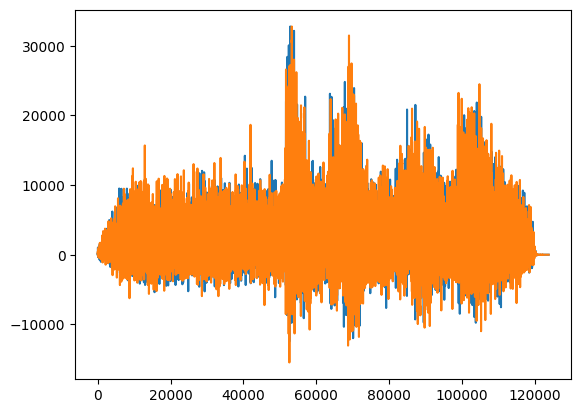

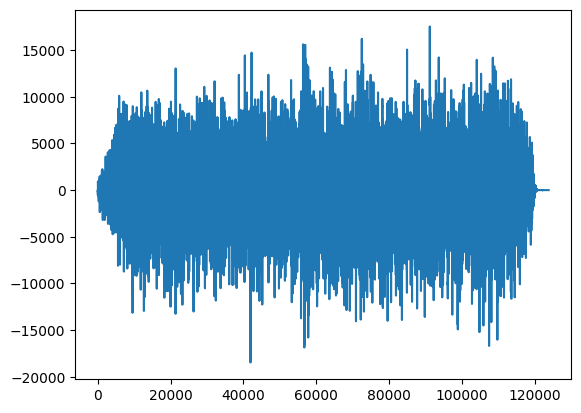

In [ ]:
from matplotlib import figure
rate_scipy, audio_scipy = wavfile.read("/content/scipy_ttr0_snr3.wav")
rate_torch, audio_torch = wavfile.read("/content/torch_ttr0_snr3.wav")

print(rate_scipy, rate_torch)
print(audio_scipy.shape, audio_torch.shape)

plt.plot(audio_scipy)
plt.plot(audio_torch)
plt.show()


# Create random speakers+batches+words

In [ ]:
import os, random, csv
import scipy.io as sio

ROOT = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio"
VOICES = ["F1","F2","F3","F4","M1","M2","M3","M4","M5"]
N_BATCH = 50
N_WORDS_PER_BATCH = 6
SEED = 123

WORDS_MAT = os.path.join(ROOT, "Words.mat")
MAT_VAR = "Words"

csv_batches = os.path.join("/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/Vocoded_stimulus/", "shuffled_batches_acc_stimulus.csv")

all_rows = []
fnames = []
for voice in VOICES:
    for b in range(1, N_BATCH+1):
        for w in range(1, N_WORDS_PER_BATCH+1):
            if voice == "M5" and b <=9:
                fname = f"{voice}_b0{b}_w{w}_orig.wav"
                ouputname = f"{voice}_b0{b}_w{w}_orig"
            else:
                fname = f"{voice}_b{b}_w{w}_orig.wav"
                ouputname = f"{voice}_b{b}_w{w}_orig"
            fnames.append(ouputname)
            fpath = os.path.join(ROOT, voice, fname)
            all_rows.append((fpath, voice, b, w))

random.seed(SEED)
paired = list(zip(fnames, all_rows))
random.shuffle(paired)
fnames, all_rows = zip(*paired)
fnames, all_rows = list(fnames), list(all_rows)

for p in all_rows[:10]:
    print(p)

print(len(all_rows))


with open("/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/all_paths.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["path"])
    for row in all_rows:
        writer.writerow([row[0]])

with open("/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/all_paths_with_meta.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["path", "voice", "batch", "word"])
    for row in all_rows:
        writer.writerow(row)

paths_array = np.array([row[0] for row in all_rows]).reshape(-1, 1)

print(fnames[:10])

if os.path.exists(WORDS_MAT):
    mat = sio.loadmat(WORDS_MAT, squeeze_me=True, struct_as_record=False)
    if MAT_VAR not in mat:
        raise KeyError(f"Variable '{MAT_VAR}' not found in {WORDS_MAT}. Keys: {list(mat.keys())}")
    words_mat = mat[MAT_VAR]  # expected shape (50, 6)
    if words_mat.shape != (50, 6):
        print("WARNING:", "Words.mat shape is", words_mat.shape, "expected (50, 6)")

    with open(csv_batches, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["path", "voice", "batch", "word_index", "output_stem", "w1", "w2", "w3", "w4", "w5", "w6"])
        for (output_stem, (path, voice, b, w_idx)) in zip(fnames, all_rows):
            # get all 6 words for this batch b
            wlist = [str(words_mat[b-1, wi]) for wi in range(words_mat.shape[1])]
            writer.writerow([path, voice, b, w_idx, output_stem, *wlist])


('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/M1/M1_b6_w4_orig.wav', 'M1', 6, 4)
('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/M4/M4_b4_w4_orig.wav', 'M4', 4, 4)
('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/M3/M3_b47_w6_orig.wav', 'M3', 47, 6)
('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/F3/F3_b33_w1_orig.wav', 'F3', 33, 1)
('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/F3/F3_b49_w2_orig.wav', 'F3', 49, 2)
('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/M5/M5_b35_w4_orig.wav', 'M5', 35, 4)
('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/F3/F3_b39_w4_orig.wav', 'F3', 39, 4)
('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/M4/M4_b34_w4_orig.wav', 'M4', 34, 4)
('/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/M2/M2_b19_w3_orig.wav', 'M2', 19,

In [ ]:
paths = paths_array.ravel().tolist()

# Generate stimulus

In [ ]:
ttrs = [40, 30, 20, 10, 0, -10]
# ttr40_snr = [-10,-5,0,5,10,15,20,25]
ttr40_snr = [-30, -24, -18, -12, -6, 0, 6, 12]
# ttr30_snr = [-10,-5,0,5,10,15,20,25]
ttr30_snr = [-30, -24, -18, -12, -6, 0, 6, 12]
# ttr20_snr = [-5,0,5,10,15,20,25]
ttr20_snr = [-25, -19, -13, -7, -1, 7, 13, 19]
# ttr10_snr = [-5,0,5,10,15,20,25,30
ttr10_snr = [-19, -13, -7, -1, 7, 13, 19, 25]
# ttr0_snr = [0,5,10,15,20,25,30,35]
ttr0_snr = [-20, -14, -8, -2, 4, 10, 16, 22, 28]
# ttr_neg10_snr = [5,10,15,20,25,30,35,40]
ttr_neg10_snr = [-15, -9, -3, 3, 9, 15, 21, 27, 33]

for ttr=-10, 30 was easy, so maybe 10,15,20,25,30,35,40 ||
for ttr=0, 25 is good, so 5,10,15,20,25,30,35 ||
ttr=10, 0,5,10,15,20,25,30
ttr=20, 0,5,10,15,20,25
ttr=30, -5,0,5,10,15,20,25
ttr=40, -5,0,5,10,15,20,25


In [ ]:
ROOT = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio"
i = 0
ttrs = [40, 30, 20, 10, 0, -10]
for ttr in ttrs:
    print(f"Processing TTR = {ttr} dB")
    if ttr == 40:
        snrs = ttr40_snr
    elif ttr == 30:
        snrs = ttr30_snr
    elif ttr == 20:
        snrs = ttr20_snr
    elif ttr == 10:
        snrs = ttr10_snr
    elif ttr == 0:
        snrs = ttr0_snr
    elif ttr == -10:
        snrs = ttr_neg10_snr

    for snr in snrs:
      for n in range(10):
        print(f"TTR = {ttr}, SNR = {snr} dB")
        audio = paths[i]
        fname = fnames[i]
        print(f"    Processing {fname}")
        i += 1
        rate, audio =  wavfile.read(audio)
        print(rate)
        audio = audio.astype(np.float32)

        duration_seconds = (audio.shape[0]) / rate
        duration_seconds = duration_seconds + 1
        speech_noise = speech_shaped_noise(rate, duration_seconds, 0)

        signal_power = np.mean(audio**2)
        noise_power = np.mean(speech_noise**2)

        # Calculate scaling factor for noise to achieve desired SNR
        snr_linear = ct.db2mag(snr)
        desired_noise_power = signal_power / snr_linear
        scale_factor = (np.sqrt(desired_noise_power / noise_power))
        padding = len(speech_noise) - len(audio)
        audio_paddedtonoise = np.concatenate((np.zeros(padding), audio))
        noise_scaled = speech_noise * scale_factor
        noisy_signal = audio_paddedtonoise + noise_scaled
        nv = noisevocode(noisy_signal, rate, ttr=ttr, nfilts=24)
        nv = nv[500:]
        output_filename = f"{fname}_ttr{ttr}_snr{snr}.wav"
        output_path = os.path.join(ROOT, "Vocoded_stimulus", output_filename)
        print(n)

        # label = f"{ttr}_gammatonetip_{bw_broadness_factor:.2f}_snr5"
        if ttr == 40 or ttr == 0 or ttr == -10:
          display(Markdown(f"**{output_filename}**"))
          display(Audio(nv[500:], rate=rate))
        sf.write(f'/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/Vocoded_stimulus_Mar2026/SharadhiMar2026_{fname}_ttr{ttr}_snr{snr}.wav', nv, rate)
        print(f"    Saved")


# Generate stimulus json

In [ ]:
SEED = 42

DRIVE_FOLDER = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/Vocoded_stimulus_new/"
MAT_FILE     = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/Words.mat"
OUTPUT_JSON  = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/Vocoded_stimulus_Mar2026/Vocoded_stimulus_new.json"

TTR_DESC = True
PICK_WITHIN_BIN = "random"
SHUFFLE_REST = True

import os, re, json, random
import numpy as np
from collections import defaultdict
from scipy.io import loadmat


def load_words_from_mat(mat_path, varname=None):
    m = loadmat(mat_path, squeeze_me=True, struct_as_record=False)

    if varname is not None:
        if varname not in m:
            raise KeyError(f"Variable '{varname}' not found in {mat_path}. Keys: {list(m.keys())}")
        cell = m[varname]
        if not (isinstance(cell, np.ndarray) and cell.dtype == object and cell.ndim == 2):
            raise ValueError(f"Variable '{varname}' is not a 2D object (cell) array.")
    else:
        candidates = []
        for k, v in m.items():
            if k.startswith("__"):
                continue
            if isinstance(v, np.ndarray) and v.dtype == object and v.ndim == 2:
                candidates.append((k, v))
        if not candidates:
            raise ValueError("No 2D object (cell) array found in the .mat file.")
        candidates.sort(key=lambda kv: abs(kv[1].shape[0]-50) + abs(kv[1].shape[1]-6))
        varname, cell = candidates[0]
        print(f"[INFO] Auto-selected MAT variable: {varname} with shape {cell.shape}")

    def to_str(x):
        if isinstance(x, str):
            return x
        if isinstance(x, np.ndarray) and x.size == 1:
            return str(x.item())
        return str(x)

    table = [[to_str(cell[i, j]).strip() for j in range(cell.shape[1])]
             for i in range(cell.shape[0])]
    return table


b_regex   = re.compile(r'(?i)[_-]b0*(\d+)(?=[_-])')
w_regex   = re.compile(r'(?i)[_-]w0*(\d+)(?=[_.-]|$)')
ttr_regex = re.compile(r'(?i)[_-]ttr([+-]?\d+)(?=[_.-]|$)')
snr_regex = re.compile(r'(?i)[_-]snr([+-]?\d+)(?=[_.-]|$)')


def build_trials_two_phase(folder, words_table):
    wavs = [f for f in os.listdir(folder) if f.lower().endswith(".wav")]
    parsed = []
    skipped = []

    for fname in wavs:
        bm = b_regex.search(fname)
        wm = w_regex.search(fname)
        tm = ttr_regex.search(fname)
        sm = snr_regex.search(fname)
        if not (bm and wm and tm and sm):
            skipped.append((fname, "Missing b/w/ttr/snr token"))
            continue
        b = int(bm.group(1))     # 1-based
        w = int(wm.group(1))     # 1-based
        ttr = int(tm.group(1))
        snr = int(sm.group(1))
        parsed.append((fname, b, w, ttr, snr))

    bins = defaultdict(list)
    for fname, b, w, ttr, snr in parsed:
        bins[(snr, ttr)].append((fname, b, w))

    if SEED is not None:
        random.seed(SEED)

    chosen_A = []
    chosen_names = set()

    ttr_levels_all = sorted({ttr for (_snr, ttr) in bins.keys()}, reverse=TTR_DESC)
    for ttr in ttr_levels_all:
        snr_levels = sorted({snr for (snr, t) in bins.keys() if t == ttr}, reverse=True)
        for snr in snr_levels:
            items = bins[(snr, ttr)]
            if not items:
                continue
            if PICK_WITHIN_BIN == "random":
                local = items[:]
                rng = random.Random(f"{SEED}-{snr}-{ttr}") if SEED is not None else random
                rng.shuffle(local)
                pick = local[0]
            else:
                pick = items[0]
            chosen_A.append(pick)
            chosen_names.add(pick[0])

    rest = [(fname, b, w) for (fname, b, w, _ttr, _snr) in parsed if fname not in chosen_names]
    if SHUFFLE_REST:
        rng = random.Random(f"{SEED}-rest") if SEED is not None else random
        rng.shuffle(rest)

    ordered = chosen_A + rest

    trials = []
    for fname, b, w in ordered:
        b_idx = b - 1
        w_idx = w - 1

        if not (0 <= b_idx < len(words_table)):
            skipped.append((fname, f"Row b{b} out of range for words table"))
            continue

        row_words = words_table[b_idx]
        if len(row_words) < 6:
            skipped.append((fname, f"Row b{b} does not have 6 words"))
            continue

        if not (0 <= w_idx < len(row_words)):
            skipped.append((fname, f"w{w} out of range for row b{b}"))
            continue

        trials.append({
            "plugin": "hari-audio-button-response",
            "prompt": "Please select the word _______",
            "choices": row_words,
            "stimulus": fname,
            "answer": int(w),
            "cond": 1,
            "annot": {"condname": "Parida, S., (2022)"}
        })

    return trials, skipped


MAT_VAR = None
words_table = load_words_from_mat(MAT_FILE, varname=MAT_VAR)
trials, skipped = build_trials_two_phase(DRIVE_FOLDER, words_table)

config = {
  "instructions": [
    "Great! Welcome to the task. To begin, make sure you are still wearing your headphones or earphones. Once you are ready, click Continue for further instructions.",
    "On each screen, you will hear a sentence along with some background noise. Please select the word _______. Your task is to pick the word that was said from the 6 words on the screen."
  ],
  "feedback": True,
  "holdfeedback": False,
  "feedbackdur": 600,
  "serveraudio": True,
  "estimatedduration": 4,
  "randomize": False,
  "isi": 600,
  "volume": [
    {
      "plugin": "html-button-response",
      "prompt": "Welcome! This task involves listening to sounds and providing responses. As a first step, we need to set an appropriate volume level for our task. Please bring down your computer volume to 10–20% of maximum. Then, click Continue to proceed.",
      "choices": ["Continue"]
    },
    {
      "plugin": "hari-audio-button-response",
      "prompt": "Now adjust your computer volume up to a comfortable (but not too loud) level.",
      "stimulus": "volumeSetStim.wav",
      "choices": ["I have adjusted the volume, let's continue"]
    },
    {
      "plugin": "html-button-response",
      "prompt": "Thanks for adjusting the volume. We will use this volume setting for the remainder of the task. Please do not adjust the volume anymore throughout the task. If this sounds OK, click Continue to begin the task.",
      "choices": ["Continue"]
    }
  ],
  "trials": trials
}

os.makedirs(os.path.dirname(OUTPUT_JSON), exist_ok=True)
with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print(f"Wrote {len(trials)} trials → {OUTPUT_JSON}")
if skipped:
    print("\nSkipped files (first 20):")
    for fname, reason in skipped[:20]:
        print(f" - {fname}: {reason}")
    if len(skipped) > 20:
        print(f"... and {len(skipped) - 20} more")


[INFO] Auto-selected MAT variable: Words with shape (50, 6)
Wrote 470 trials → /content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/Vocoded_stimulus_Mar2026/Vocoded_stimulus_new.json


# Results

## Read results json and create table

In [ ]:
import json
import re
from pathlib import Path

import pandas as pd

input_json   = "/content/mrtDTsimSharadhi_hari_results (4).json"
summary_xlsx = "/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/ttr_snr_summary.xlsx"

ttr_snr_re = re.compile(r"_ttr(-?\d+)_snr(-?\d+)\.wav$", re.IGNORECASE)

if Path(summary_xlsx).exists():
    existing = pd.read_excel(summary_xlsx)
    known_subjects = set(existing["subject"].astype(str))
else:
    existing = pd.DataFrame(columns=["subject", "ttr", "snr", "n_trials", "n_correct", "accuracy"])
    known_subjects = set()


text = Path(input_json).read_text(encoding="utf-8")
dec = json.JSONDecoder()
trials = []
idx = 0
while idx < len(text):
    while idx < len(text) and text[idx].isspace():
        idx += 1
    if idx >= len(text):
        break
    if text[idx] != "[":
        idx += 1
        continue
    arr, idx = dec.raw_decode(text, idx)
    stack = [arr]
    while stack:
        cur = stack.pop()
        if isinstance(cur, dict):
            trials.append(cur)
        elif isinstance(cur, list):
            stack.extend(cur)

rows = []
skipped_subjects = set()
for t in trials:
    if t.get("trial_type") != "hari-audio-button-response":
        continue
    subj = str(t.get("subject", "UNKNOWN"))
    if subj in known_subjects:
        skipped_subjects.add(subj)
        continue
    m = ttr_snr_re.search(t.get("stimulus", ""))
    if not m:
        continue
    rows.append({
        "subject": subj,
        "ttr": int(m.group(1)),
        "snr": int(m.group(2)),
        "correct": bool(t.get("correct", False)),
    })


if skipped_subjects:
    print(f"Already in summary, skipped: {sorted(skipped_subjects)}")

if not rows:
    print("No new subjects to add.")
else:
    df = pd.DataFrame(rows)
    new_summary = df.groupby(["subject", "ttr", "snr"], as_index=False).agg(
        n_trials=("correct", "size"),
        n_correct=("correct", "sum"),
    )
    new_summary["accuracy"] = (new_summary["n_correct"] / new_summary["n_trials"]).round(3)

    combined = pd.concat([existing, new_summary], ignore_index=True)
    combined = combined.sort_values(["subject", "ttr", "snr"]).reset_index(drop=True)
    combined.to_excel(summary_xlsx, index=False)
    print(f"Added subjects: {sorted(df['subject'].unique())}")
    print(f"Wrote: {summary_xlsx}")

## Plotting results

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/ttr_snr_summary.xlsx")

df["percent_correct"] = df["accuracy"] * 100

subjects = df["subject"].unique()

print(len(subjects))
print(subjects)

for subj in subjects:
    sub_df = df[df["subject"] == subj]
    sub_df = sub_df.sort_values(by=["ttr", "snr"])

    unique_ttrs = sorted(sub_df["ttr"].unique())
    offsets = np.linspace(-0.6, 0.6, len(unique_ttrs)) / 4.0
    colors = plt.cm.plasma(np.linspace(0.9, 0.1, len(unique_ttrs)))

    plt.figure(figsize=(8,6))
    for i, ttr_val in enumerate(unique_ttrs):
        g = sub_df[sub_df["ttr"] == ttr_val].sort_values("snr")
        plt.plot(
            g["snr"] + offsets[i],
            g["percent_correct"],
            label=f"TTR {ttr_val}",
            color=colors[i],
            marker="o",
            linewidth=1.2,
            markersize=6,
            markeredgecolor="black",
            markeredgewidth=0.4,
        )

    plt.xlabel("SNR (dB)")
    plt.ylabel("Percent Correct (%)")
    plt.title(f"Performance vs SNR — {subj}")
    plt.legend(title="TTR")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

group = (df.groupby(["ttr", "snr"])["percent_correct"]
           .agg(["mean", "sem"])
           .reset_index())
n_subj = df["subject"].nunique()

unique_ttrs = sorted(group["ttr"].unique())
offsets = np.linspace(-0.6, 0.6, len(unique_ttrs)) / 4.0
colors = plt.cm.plasma(np.linspace(0.9, 0.1, len(unique_ttrs)))

plt.figure(figsize=(8, 6))
for i, ttr_val in enumerate(unique_ttrs):
    g = group[group["ttr"] == ttr_val].sort_values("snr")
    plt.errorbar(
        g["snr"] + offsets[i],
        g["mean"],
        yerr=g["sem"],
        label=f"TTR {ttr_val}",
        color=colors[i],
        marker="o",
        linewidth=1.2,
        markersize=6,
        markeredgecolor="black",
        markeredgewidth=0.4,
        capsize=3,
        elinewidth=1.0,
    )

plt.xlabel("SNR (dB)")
plt.ylabel("Percent Correct (%)")
plt.title(f"Group Average  (N = {n_subj}, ± SEM)")
plt.legend(title="TTR")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Psychometric curves - psignifit

In [ ]:
!pip install psignifit

In [ ]:
import psignifit as ps
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import psignifit.psigniplot as psp
import matplotlib.lines as mlines

df = pd.read_excel("/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/ttr_snr_summary.xlsx")

df["percent_correct"] = df["accuracy"] * 100
subjects = df["subject"].unique()
print(len(subjects))
N_trials = 10

group_df = (
    df.groupby(["ttr", "snr"])
      .agg(
          total_correct=("accuracy",lambda x: np.sum(x * N_trials)), n_subjects=("subject", "nunique"))
      .reset_index())

group_df["total_trials"] = (group_df["n_subjects"] * N_trials)

group_df["proportion_correct"] = (
    group_df["total_correct"] /
    group_df["total_trials"]
)

for subj in subjects:
    sub_df = df[df["subject"] == subj]
    sub_df = sub_df.sort_values(by=["ttr", "snr"])

    unique_ttrs = sorted(sub_df["ttr"].unique())
    offsets = np.linspace(-0.6, 0.6, len(unique_ttrs)) / 4.0
    colors = plt.cm.plasma(np.linspace(0.9, 0.1, len(unique_ttrs)))

    fig, ax = plt.subplots(figsize=(7, 5))
    legend_handles = []

    for ttr_val, col in zip(unique_ttrs, colors):
        g = (
        group_df[group_df["ttr"] == ttr_val]
        .sort_values("snr")
    )
        g = sub_df[sub_df["ttr"] == ttr_val].sort_values("snr")
        x = g["snr"].to_numpy(dtype=float)
        k = np.round(g["accuracy"].to_numpy() * N_trials).astype(int)
        n = np.full_like(k, N_trials)
        data = np.column_stack([x, k, n]).astype(float)

        res = ps.psignifit(data, sigmoid='logistic', experiment_type='6AFC', grid_steps={'lambda': 50})
        # print(res.parameter_estimate)
        psp.plot_psychometric_function(
            res,
            ax=ax,
            line_color=col,
            data_color=col,
            plot_parameter=False,
            x_label="SNR (dB)",
            y_label="Proportion Correct",
        )

        legend_handles.append(mlines.Line2D([], [], color=col,
                                            marker='o', linestyle='-',
                                            label=f"TTR {ttr_val}"))

    ax.set_title(f"Performance vs SNR — {subj}")
    ax.legend(handles=legend_handles, title="TTR")
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


### Group average

In [ ]:
!pip install psignifit


SNR Thresholds at 80% Correct (from fitted curves):
TTR 40: 1.82 dB
TTR 25: -1.10 dB
TTR 5: 5.14 dB
TTR -10: 16.98 dB



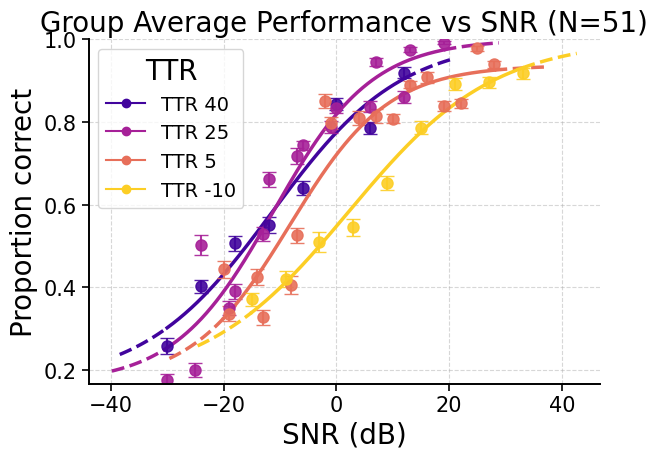

In [ ]:
import psignifit as ps
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import psignifit.psigniplot as psp

plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size':          20,
    'axes.titlesize':     20,
    'axes.labelsize':     20,
    'xtick.labelsize':    15,
    'ytick.labelsize':    15,
    'legend.fontsize':    14,
    'axes.linewidth':     1.4,
    'xtick.major.width':  1.2,
    'ytick.major.width':  1.2,
    'xtick.major.size':   5,
    'ytick.major.size':   5,
    'xtick.minor.width':  0.8,
    'ytick.minor.width':  0.8,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})


df = pd.read_excel("/content/drive/MyDrive/SNAPlab/Vocoded_audios/Vocode_MRT_sentences/audio/ttr_snr_summary.xlsx")

N_TRIALS = 10

ttr_to_group = {
     40: "40",
     30: "25",
     20: "25",
     10:  "5",
      0:  "5",
    -10: "-10",
}
df["ttr_group"] = df["ttr"].map(ttr_to_group)

group_df = (df.groupby(["ttr_group", "snr"]).agg(
          mean_accuracy=("accuracy", "mean"),
          sem_accuracy=("accuracy", "sem"),
          total_correct=("accuracy",
                         lambda x: np.sum(x * N_TRIALS)),
          n_subjects=("subject", "nunique")
      )
      .reset_index()
)

group_df["total_trials"] = group_df["n_subjects"] * N_TRIALS
group_df["proportion_correct"] = group_df["total_correct"] / group_df["total_trials"]

group_order = ["40", "25", "5", "-10"]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(group_order)))

fig, ax = plt.subplots(figsize=(6.5, 5.0))
legend_handles = []


thresholds = []

for i, ttr_label in enumerate(group_order):
    col = colors[i]
    g = group_df[group_df["ttr_group"] == ttr_label].sort_values("snr")

    x = g["snr"].to_numpy(dtype=float)
    k = g["total_correct"].to_numpy(dtype=int)
    n = g["total_trials"].to_numpy(dtype=int)
    data = np.column_stack([x, k, n]).astype(float)

    res = ps.psignifit(data,sigmoid='logistic',experiment_type='6AFC',grid_steps={'lambda': 50})
    threshold_80 = res.threshold(0.8)[0]
    thresholds.append({'TTR': ttr_label, 'Threshold_80pct': threshold_80})

    ax.errorbar(
        g["snr"], g["mean_accuracy"],
        yerr=g["sem_accuracy"],
        fmt='o', color=col, markersize=8, capsize=5, alpha=0.9)

    psp.plot_psychometric_function(
        res, ax=ax,
        line_color=col, data_color=col,
        line_width=2.5,
        plot_parameter=False, plot_data=False,
        x_label="", y_label="")

    legend_handles.append(mlines.Line2D([], [], color=col, marker='o',
                                        linestyle='-',
                                        label=f"TTR {ttr_label}"))

print("\n" + "="*50)
print("SNR Thresholds at 80% Correct (from fitted curves):")
print("="*50)
threshold_df = pd.DataFrame(thresholds)
for idx, row in threshold_df.iterrows():
    print(f"TTR {row['TTR']}: {row['Threshold_80pct']:.2f} dB")
print("="*50 + "\n")

n_subj = df["subject"].nunique()
ax.set_title(f"Group Average Performance vs SNR (N={n_subj})")
ax.set_xlabel("SNR (dB)", fontsize=20)
ax.set_ylabel("Proportion correct", fontsize=20)
ax.legend(handles=legend_handles, title="TTR")
ax.grid(True, linestyle="--", alpha=0.5)
plt.savefig('TTRvsSNR_average_psychometric.jpeg',bbox_inches='tight')
plt.savefig('TTRvsSNR_average_psychometric.pdf',bbox_inches='tight')
plt.tight_layout()
plt.show()

# Random

audio.wav           100%[===================>] 181.96K  --.-KB/s    in 0.06s   


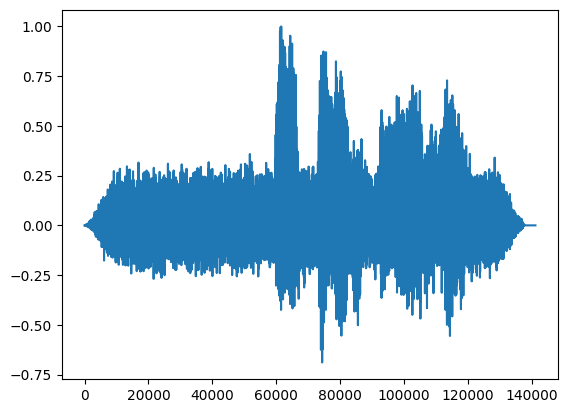

In [ ]:
i = 45
# link = url['Links'][i]
# i+=1
!wget -q --show-progress -O audio.wav "https://www.dropbox.com/scl/fo/f54r9lh3ub5asrntvl1uk/AN4Omn0YTjdC6nnm2xWCoAk/F1/F1_b1_w1_orig.wav?rlkey=n4m4nhxpnb1bco8w9igpxx3cb&dl=1"
rate, audio = wavfile.read("audio.wav")
audio = audio.astype(np.float32)
# pad = 2000 # Pad the audio to avoid edge effects during processing
# audio = np.concatenate((np.zeros(pad), audio))

duration_seconds = (audio.shape[0]) / rate
duration_seconds = duration_seconds + 1
speech_noise = speech_shaped_noise(rate, duration_seconds, 0.2)

## Calculate power of signal and noise
signal_power = np.mean(audio**2)
noise_power = np.mean(speech_noise**2)

# Calculate scaling factor for noise to achieve desired SNR
snr_linear = ct.db2mag(10)
desired_noise_power = signal_power / snr_linear
scale_factor = (np.sqrt(desired_noise_power / noise_power))
padding = len(speech_noise) - len(audio)
audio_paddedtonoise = np.concatenate((np.zeros(padding), audio))
noise_scaled = speech_noise * scale_factor
noisy_signal = audio_paddedtonoise + noise_scaled
nv = noisevocode(noisy_signal, rate, ttr=0, bw_broadness_factor=1, nfilts=24)
plt.plot(nv)
ttr=0
bw_broadness_factor=1
# sf.write(f'/content/drive/MyDrive/SNAPlab/Vocoded_audios/New_trial/ttr{ttr}_gammatonetip_{bw_broadness_factor}_snr{5}.wav',nv.astype(np.float32), rate, subtype="FLOAT")
# wavfile.write(f'/content/drive/MyDrive/SNAPlab/Vocoded_audios/New_trial/ttr{ttr}_gammatonetip_{bw_broadness_factor}_snr{5}.wav', rate, nv[pad:])
remove = 100
Audio(nv[500:], rate=rate)

## SNR = 5

In [ ]:
snr=5
i = 7
for ttr in ttrs:
  for bw_broadness_factor in gt_bw_broadness_factors:
    link = url['Links'][i]
    i+=1
    !wget -q --show-progress -O audio.wav "$link"
    rate, audio = wavfile.read("audio.wav")
    audio = audio.astype(np.float32)

    duration_seconds = (audio.shape[0]) / rate
    duration_seconds = duration_seconds + 1
    speech_noise = speech_shaped_noise(rate, duration_seconds, 0)

    ## Calculate power of signal and noise
    signal_power = np.mean(audio**2)
    noise_power = np.mean(speech_noise**2)

    # Calculate scaling factor for noise to achieve desired SNR
    snr_linear = ct.db2mag(snr)
    desired_noise_power = signal_power / snr_linear
    scale_factor = (np.sqrt(desired_noise_power / noise_power))
    padding = len(speech_noise) - len(audio)
    audio_paddedtonoise = np.concatenate((np.zeros(padding), audio))
    noise_scaled = speech_noise * scale_factor
    noisy_signal = audio_paddedtonoise + noise_scaled
    nv = noisevocode(noisy_signal, rate, ttr=ttr, phase_diff=True, bw_broadness_factor=bw_broadness_factor, nfilts=24)
    nv = nv[500:]
    label = f"{ttr}_gammatonetip_{bw_broadness_factor:.2f}_snr5"
    display(Markdown(f"**{label}**"))
    display(Audio(nv[500:], rate=rate))
    sf.write(f'/content/drive/MyDrive/SNAPlab/Vocoded_audios/ttr{ttr}_gammatonetip_{bw_broadness_factor}_snr{5}_neg.wav',nv.astype(np.float32), rate, subtype="FLOAT")
